Next: Mini Pandas project — Sales Data Analysis
We'll use a small dataset and practice real-world operations: cleaning, calculating revenue, grouping, sorting and summarizing.

Step 1 — Create the dataset

Run this in your VS Code Jupyter Notebook:
our first task: Calculate a new column called Revenue using:
\[
                  Revenue = Price  * Quantity
\]

Try writing the code yourself. I'll check it before we move to the next step.

In [14]:
import pandas as pd

df = pd.DataFrame({
    "Product": ["Laptop", "Mobile", "Laptop", "Tablet", "Mobile", "Tablet"],
    "Category": ["Electronics", "Electronics", "Electronics",
                 "Electronics", "Electronics", "Electronics"],
    "Price": [50000, 20000, 50000, 15000, 20000, 15000],
    "Quantity": [2, 3, 1, 4, 2, 3],
    "City": ["Hyderabad", "Delhi", "Mumbai", "Hyderabad",
             "Delhi", "Mumbai"]
})

df


,Product,Category,Price,Quantity,City
0,Laptop,Electronics,50000,2,Hyderabad
1,Mobile,Electronics,20000,3,Delhi
2,Laptop,Electronics,50000,1,Mumbai
3,Tablet,Electronics,15000,4,Hyderabad
4,Mobile,Electronics,20000,2,Delhi
5,Tablet,Electronics,15000,3,Mumbai


In [15]:
df['Revenue']=df['Price']*df['Quantity']
df

,Product,Category,Price,Quantity,City,Revenue
0,Laptop,Electronics,50000,2,Hyderabad,100000
1,Mobile,Electronics,20000,3,Delhi,60000
2,Laptop,Electronics,50000,1,Mumbai,50000
3,Tablet,Electronics,15000,4,Hyderabad,60000
4,Mobile,Electronics,20000,2,Delhi,40000
5,Tablet,Electronics,15000,3,Mumbai,45000


Next task
Create a new column called Total_Products that contains the total quantity sold for all rows.

Hint: Use df["Quantity"].sum().

In [16]:
df['Quantity'].sum()
df

,Product,Category,Price,Quantity,City,Revenue
0,Laptop,Electronics,50000,2,Hyderabad,100000
1,Mobile,Electronics,20000,3,Delhi,60000
2,Laptop,Electronics,50000,1,Mumbai,50000
3,Tablet,Electronics,15000,4,Hyderabad,60000
4,Mobile,Electronics,20000,2,Delhi,40000
5,Tablet,Electronics,15000,3,Mumbai,45000


Next task
Find the total revenue of all products.

In [17]:
df['Revenue'].sum()

np.int64(355000)

Next task — Find revenue by product
Use groupby() to calculate the total revenue for each product.

Expected output:
Product	Revenue
Laptop	150000
Mobile	100000
Tablet	105000

In [18]:
df.groupby('Product')['Revenue'].sum()

Product
Laptop    150000
Mobile    100000
Tablet    105000
Name: Revenue, dtype: int64

Step 3 — Find the highest-revenue product
Now let's find which product generated the highest total revenue.

Hint: You already know groupby() and sum(). You can use .idxmax() to get the product name with the highest value.

In [19]:
df.groupby('Product')['Revenue'].sum().idxmax()

'Laptop'

Next practice
Find the average revenue for each product.

Hint: Use groupby() and .mean().

Try it yourself!

In [20]:
df.groupby('Product')['Revenue'].mean()

Product
Laptop    75000.0
Mobile    50000.0
Tablet    52500.0
Name: Revenue, dtype: float64

Sort products by revenue
Sort the original DataFrame by Revenue from highest to lowest.

In [21]:
df.sort_values(by='Revenue', ascending=False)

,Product,Category,Price,Quantity,City,Revenue
0,Laptop,Electronics,50000,2,Hyderabad,100000
1,Mobile,Electronics,20000,3,Delhi,60000
3,Tablet,Electronics,15000,4,Hyderabad,60000
2,Laptop,Electronics,50000,1,Mumbai,50000
5,Tablet,Electronics,15000,3,Mumbai,45000
4,Mobile,Electronics,20000,2,Delhi,40000


Next task — Find the top 2 products by total revenue
We need to:
1. Group by Product.
2. Calculate total Revenue.
3. Sort from highest to lowest.
4. Select the top 2.
Hint: Combine groupby(), sum(), sort_values() and head(2).

In [22]:
df.groupby('Product')['Revenue'].sum().sort_values(ascending=False).head(2)

Product
Laptop    150000
Tablet    105000
Name: Revenue, dtype: int64

Next task — Find total revenue by city
Use groupby() to calculate the total revenue for each city.

#Hint: Replace Product with City.

Try it yourself!

In [23]:
df.groupby('City')['Revenue'].sum()

City
Delhi        100000
Hyderabad    160000
Mumbai        95000
Name: Revenue, dtype: int64

Next task — Create a Pivot Table
Now combine two Pandas concepts you learned earlier.

Task: Calculate total revenue for each Product in each City.

In [24]:
df.pivot_table(
    index='Product',
    columns='City',
    values='Revenue',
    aggfunc='sum'
)

City,Delhi,Hyderabad,Mumbai
Product,,,
Laptop,NaN,100000.0,50000.0
Mobile,100000.0,NaN,NaN
Tablet,NaN,60000.0,45000.0


Next task — Find the best-selling product
Find which product has the highest total quantity sold.

Hint: Use groupby('Product'), Quantity, .sum() and .idxmax().

In [25]:
df.groupby('Product')['Quantity'].sum().idxmax()

'Tablet'

Next task — Create a sales summary
Find these three things:
1. Total revenue.
2. Total quantity sold.
3. Average revenue.
Write code to calculate all three. You can use sum() and mean().

In [29]:
df['Revenue'].sum()   # Total revenue = 355000


np.int64(355000)

In [28]:
df['Revenue'].mean()  # Average revenue = 59166.67

np.float64(59166.666666666664)

In [27]:
df['Quantity'].sum()  # Total quantity = 15

np.int64(15)

Next task — Data visualization
Let's create a simple bar chart showing total revenue by product.

<Axes: xlabel='Product'>

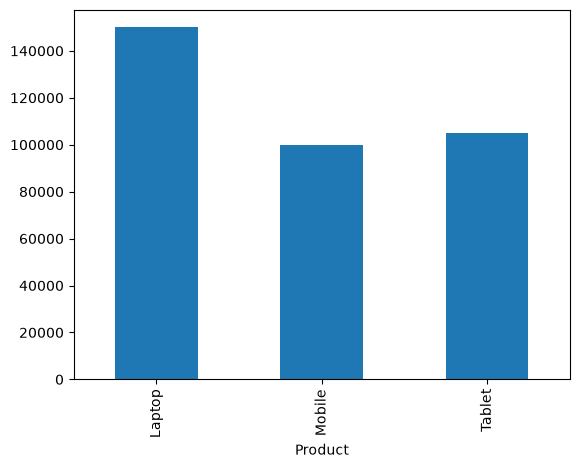

In [31]:
df.groupby('Product')['Revenue'].sum().plot(kind='bar')

Next step
Let's make your chart look professional:

In [33]:
import matplotlib.pyplot as plt
plt.show()

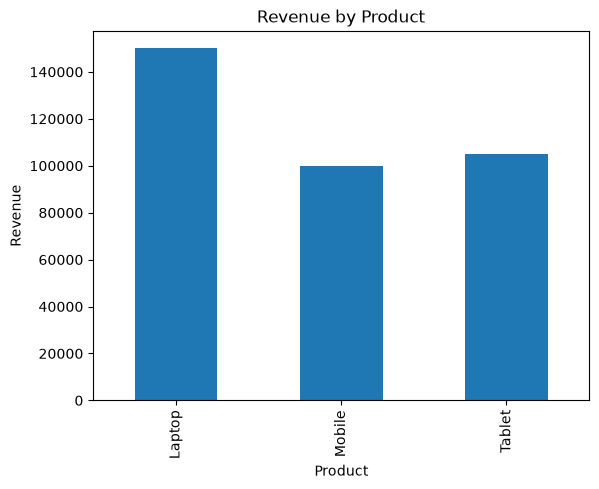

In [34]:
df.groupby('Product')['Revenue'].sum().plot(
    kind='bar',
    title='Revenue by Product',
    xlabel='Product',
    ylabel='Revenue'
)

plt.show()

Final practice — Mini project challenge
Let's test your understanding with one task at a time.

Question 1: Find the product with the highest total revenue and display only its name.

Hint: Combine groupby(), sum() and idxmax().

In [35]:
df.groupby('Product')['Revenue'].sum().idxmax()

'Laptop'

Final practice — Question 2
Find the top 2 cities by total revenue, sorted from highest to lowest.

Hint: Use groupby(), sum(), sort_values() and head(2).

Try it yourself!

In [37]:
df.groupby('City')['Revenue'].sum().sort_values(ascending=False).head(2)

City
Hyderabad    160000
Delhi        100000
Name: Revenue, dtype: int64

Question 3
Calculate the average quantity sold in each city.

Hint: Use groupby('City'), Quantity, and .mean().

Try it yourself!

In [39]:
df.groupby('City')['Quantity'].mean()

City
Delhi        2.5
Hyderabad    3.0
Mumbai       2.0
Name: Quantity, dtype: float64

Question 4
Find the city with the highest total quantity sold. Display only the city name.

Hint: Use groupby(), sum() and idxmax().

Your turn!

In [41]:
df.groupby('City')['Quantity'].sum().idxmax()

'Hyderabad'

Final Question 5 — Data analysis
Find the total revenue for each product and city, using a Pivot Table.

Use these requirements:
- Rows: Product
- Columns: City
- Values: Revenue
- Calculation: sum
Write the complete pivot_table() code yourself!

In [43]:
df.pivot_table(
    index='Product',
    columns='City',
    values='Revenue',
    aggfunc='sum'
)

City,Delhi,Hyderabad,Mumbai
Product,,,
Laptop,NaN,100000.0,50000.0
Mobile,100000.0,NaN,NaN
Tablet,NaN,60000.0,45000.0
